# 标普500波动率预测 —— 基于Google Mobility另类数据
## 机器学习期末作业 0241136002 王宇飞

---

### 项目思路

传统金融分析主要依赖价格、成交量等市场数据。**另类数据（Alternative Data）** 的兴起为市场分析提供了全新的视角。

本项目的核心思路：
- 使用 **Google Community Mobility Reports** 中的流动性变化数据作为另类数据源
- 该数据反映了疫情期间及之后人们在零售、工作场所、住宅等场所的活动变化
- 这些流动性变化可能蕴含着经济活动的信息，进而影响股市波动
- 利用机器学习方法，**用流动性数据预测标普500指数的次日波动率**

### 分析方法

1. **数据清洗**：过滤美国地区数据、按日聚合、与交易日匹配
2. **特征工程**：流动性指标、滞后特征、历史波动率
3. **三种模型**：岭回归（Ridge）、随机森林（Random Forest）、XGBoost
4. **超参数调优**：时间序列交叉验证 + GridSearchCV
5. **综合对比**：RMSE / MAE / R² + 多维度可视化

---
## 0. 环境配置与导入库

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体 & 风格
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")
print("✅ 环境配置完成")

✅ 环境配置完成


---
## 1. 数据清洗

### 1a. 读取标普500数据

In [2]:
# 先读取不解析日期，手动处理混合格式
sp500 = pd.read_csv('SP500.csv')
sp500.columns = ['date', 'open', 'high', 'low', 'close']

# 日期格式混合（1/3/2000 vs 1/13/00），统一用 format='mixed' 解析
sp500['date'] = pd.to_datetime(sp500['date'], format='mixed', dayfirst=False)
sp500 = sp500.sort_values('date').reset_index(drop=True)

print(f"标普500数据: {sp500.shape[0]} 行")
print(f"日期范围: {sp500['date'].min().date()} ~ {sp500['date'].max().date()}")

# 验证无周末数据
sp500['weekday'] = sp500['date'].dt.dayofweek
weekend_data = sp500[sp500['weekday'] >= 5]
print(f"周末数据行数: {len(weekend_data)}（标普500周末休市，应为0）")
sp500 = sp500.drop(columns=['weekday'])
sp500.head()

标普500数据: 5821 行
日期范围: 2000-01-03 ~ 2023-02-21
周末数据行数: 0（标普500周末休市，应为0）


,date,open,high,low,close
0,2000-01-03,1469.25,1478.00,1438.36,1455.22
1,2000-01-04,1455.22,1455.22,1397.43,1399.42
2,2000-01-05,1399.42,1413.27,1377.68,1402.11
3,2000-01-06,1402.11,1411.90,1392.10,1403.45
4,2000-01-07,1403.45,1441.47,1400.73,1441.47


### 1b. 读取全球流动性数据（分块读取，仅保留美国数据）

原始文件约 1.14 GB / 1173万行。使用分块读取避免内存溢出，仅保留 `country_region_code == 'US'` 的数据。

**选择美国的原因**：标普500是美国股票指数，使用美国全境的流动性数据与目标最匹配。

In [3]:
# 分块读取大文件，仅保留 US 数据
# 注意：low_memory=False 避免列类型混合警告；先过滤再解析日期以提升效率
us_mobility_chunks = []
chunk_size = 500000

for chunk in pd.read_csv('Global_Mobility_Report.csv', chunksize=chunk_size,
                         low_memory=False):
    chunk = chunk[chunk['country_region_code'] == 'US']
    us_mobility_chunks.append(chunk)
    if len(us_mobility_chunks) % 5 == 0:
        print(f"  已处理 {len(us_mobility_chunks) * chunk_size / 1e6:.0f}M 行...")

mobility = pd.concat(us_mobility_chunks, ignore_index=True)
del us_mobility_chunks  # 释放内存

# 统一解析日期（过滤后再解析，速度更快）
mobility['date'] = pd.to_datetime(mobility['date'])

print(f"美国流动性数据: {mobility.shape[0]} 行")
print(f"日期范围: {mobility['date'].min().date()} ~ {mobility['date'].max().date()}")
print(f"覆盖地区数: {mobility['sub_region_1'].nunique()}")
mobility.head()

  已处理 2M 行...
  已处理 5M 行...
  已处理 8M 行...
  已处理 10M 行...
美国流动性数据: 2511994 行
日期范围: 2020-02-15 ~ 2022-10-15
覆盖地区数: 51


,country_region_code,country_region,sub_region_1,sub_region_2,metro_area,iso_3166_2_code,census_fips_code,place_id,date,retail_and_recreation_percent_change_from_baseline,grocery_and_pharmacy_percent_change_from_baseline,parks_percent_change_from_baseline,transit_stations_percent_change_from_baseline,workplaces_percent_change_from_baseline,residential_percent_change_from_baseline
0,US,United States,NaN,NaN,NaN,NaN,NaN,ChIJCzYy5IS16lQRQrfeQ5K5Oxw,2020-02-15,6.0,2.0,15.0,3.0,2.0,-1.0
1,US,United States,NaN,NaN,NaN,NaN,NaN,ChIJCzYy5IS16lQRQrfeQ5K5Oxw,2020-02-16,7.0,1.0,16.0,2.0,0.0,-1.0
2,US,United States,NaN,NaN,NaN,NaN,NaN,ChIJCzYy5IS16lQRQrfeQ5K5Oxw,2020-02-17,6.0,0.0,28.0,-9.0,-24.0,5.0
3,US,United States,NaN,NaN,NaN,NaN,NaN,ChIJCzYy5IS16lQRQrfeQ5K5Oxw,2020-02-18,0.0,-1.0,6.0,1.0,0.0,1.0
4,US,United States,NaN,NaN,NaN,NaN,NaN,ChIJCzYy5IS16lQRQrfeQ5K5Oxw,2020-02-19,2.0,0.0,8.0,1.0,1.0,0.0


### 1c. 按日聚合流动性数据

原始数据是各子地区级别的，需要按日期聚合为全国级别的日度指标：
- 取每日各地区的 **均值**（反映全国平均流动性水平）
- 取每日各地区的 **标准差**（反映地区间差异程度）

In [4]:
mobility_cols = [
    'retail_and_recreation_percent_change_from_baseline',
    'grocery_and_pharmacy_percent_change_from_baseline',
    'parks_percent_change_from_baseline',
    'transit_stations_percent_change_from_baseline',
    'workplaces_percent_change_from_baseline',
    'residential_percent_change_from_baseline'
]

# 按日期聚合：均值和标准差
daily_mobility = mobility.groupby('date')[mobility_cols].agg(['mean', 'std']).reset_index()
daily_mobility.columns = ['date'] + [f'{col}_{stat}' for col, stat in daily_mobility.columns[1:]]
daily_mobility = daily_mobility.sort_values('date').reset_index(drop=True)
print(f"聚合后: {daily_mobility.shape[0]} 天")
daily_mobility.head()

聚合后: 974 天


,date,retail_and_recreation_percent_change_from_baseline_mean,retail_and_recreation_percent_change_from_baseline_std,grocery_and_pharmacy_percent_change_from_baseline_mean,grocery_and_pharmacy_percent_change_from_baseline_std,parks_percent_change_from_baseline_mean,parks_percent_change_from_baseline_std,transit_stations_percent_change_from_baseline_mean,transit_stations_percent_change_from_baseline_std,workplaces_percent_change_from_baseline_mean,workplaces_percent_change_from_baseline_std,residential_percent_change_from_baseline_mean,residential_percent_change_from_baseline_std
0,2020-02-15,6.438312,9.778186,2.379042,8.465544,16.656366,22.548640,4.305752,11.049218,0.440956,4.317132,-0.550773,0.695816
1,2020-02-16,7.986545,10.797762,2.510529,9.205906,17.794574,29.787309,3.750263,10.606393,0.483758,3.882378,-0.662211,0.848711
2,2020-02-17,3.865924,10.215536,-0.345273,8.113075,27.884323,32.837767,1.809293,14.193821,-17.582155,10.345179,4.363946,2.070620
3,2020-02-18,-0.193126,7.424303,-1.269536,7.570161,5.355491,21.329696,2.243528,9.228292,-0.005490,4.572573,0.794598,1.467827
4,2020-02-19,2.079837,7.372120,0.579079,7.090120,7.988456,20.013865,2.474335,9.147814,0.884461,3.788361,0.177349,1.112718


### 1d. 与标普500交易日匹配

流动性数据每天都有（包括周末），但标普500仅在工作日交易。
需要**删除周末和假日的流动性数据**，只保留与标普500交易日匹配的日期。

In [5]:
# 只保留交易日
sp500_dates = set(sp500['date'])
daily_mobility = daily_mobility[daily_mobility['date'].isin(sp500_dates)]
print(f"与标普500交易日匹配: {daily_mobility.shape[0]} 天")

# 合并
merged = sp500.merge(daily_mobility, on='date', how='inner')
print(f"合并后: {merged.shape[0]} 行 x {merged.shape[1]} 列")
merged.head(3)

与标普500交易日匹配: 672 天
合并后: 672 行 x 17 列


,date,open,high,low,close,retail_and_recreation_percent_change_from_baseline_mean,retail_and_recreation_percent_change_from_baseline_std,grocery_and_pharmacy_percent_change_from_baseline_mean,grocery_and_pharmacy_percent_change_from_baseline_std,parks_percent_change_from_baseline_mean,parks_percent_change_from_baseline_std,transit_stations_percent_change_from_baseline_mean,transit_stations_percent_change_from_baseline_std,workplaces_percent_change_from_baseline_mean,workplaces_percent_change_from_baseline_std,residential_percent_change_from_baseline_mean,residential_percent_change_from_baseline_std
0,2020-02-18,3369.04,3375.01,3355.61,3370.29,-0.193126,7.424303,-1.269536,7.570161,5.355491,21.329696,2.243528,9.228292,-0.005490,4.572573,0.794598,1.467827
1,2020-02-19,3380.39,3393.52,3378.83,3386.15,2.079837,7.372120,0.579079,7.090120,7.988456,20.013865,2.474335,9.147814,0.884461,3.788361,0.177349,1.112718
2,2020-02-20,3380.45,3389.15,3341.02,3373.23,0.179147,8.185950,-0.153623,7.804148,-1.251359,22.125692,1.944972,9.024016,-0.338203,4.470617,1.140961,1.962257


### 1e. 缺失值处理

In [6]:
missing = merged.isnull().sum()
missing_pct = (missing / len(merged) * 100).round(2)
missing_info = pd.DataFrame({'缺失数': missing, '缺失率(%)': missing_pct})
print("缺失值情况:")
print(missing_info[missing_info['缺失数'] > 0])

# 前向 + 后向填充（使用新版API）
merged = merged.ffill().bfill()
print(f"\n填充后缺失总数: {merged.isnull().sum().sum()}")

# 保存清洗后数据
merged.to_csv('cleaned_data.csv', index=False)
print("清洗后数据已保存至 cleaned_data.csv")

缺失值情况:
Empty DataFrame
Columns: [缺失数, 缺失率(%)]
Index: []

填充后缺失总数: 0
清洗后数据已保存至 cleaned_data.csv


---
## 2. 特征工程

### 2a. 构建目标变量 —— 次日波动率

使用日内振幅 `(High - Low) / Close × 100` 作为波动率度量，预测其次日值。

目标变量（次日波动率 %）统计:
  均值: 1.519%
  标准差: 1.095%
  范围: [0.169%, 8.077%]


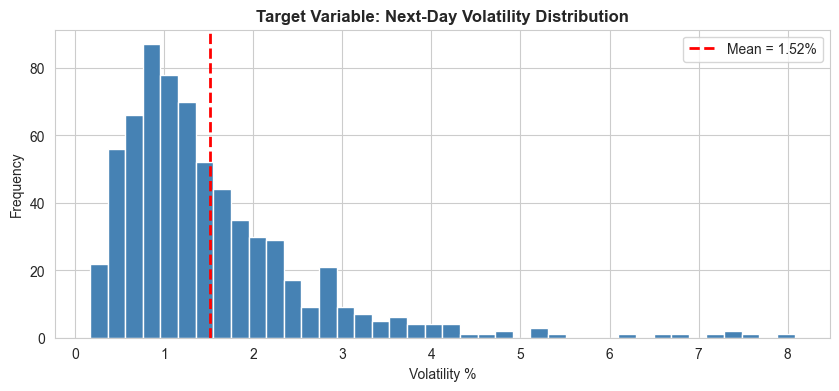

In [7]:
# 日内振幅（波动率度量）
merged['daily_range'] = (merged['high'] - merged['low']) / merged['close'] * 100

# 收益率
merged['return'] = merged['close'].pct_change() * 100

# 目标变量：次日波动率
merged['target_volatility'] = merged['daily_range'].shift(-1)

print("目标变量（次日波动率 %）统计:")
print(f"  均值: {merged['target_volatility'].mean():.3f}%")
print(f"  标准差: {merged['target_volatility'].std():.3f}%")
print(f"  范围: [{merged['target_volatility'].min():.3f}%, {merged['target_volatility'].max():.3f}%]")

# 直方图
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(merged['target_volatility'].dropna(), bins=40, color='steelblue', edgecolor='white')
ax.axvline(merged['target_volatility'].mean(), color='red', linestyle='--', linewidth=2,
           label=f'Mean = {merged["target_volatility"].mean():.2f}%')
ax.set_xlabel('Volatility %'); ax.set_ylabel('Frequency')
ax.set_title('Target Variable: Next-Day Volatility Distribution', fontweight='bold')
ax.legend()


### 2b. 构建特征矩阵

特征设计：
1. **流动性均值特征**（6个）：各场所每日全国均值
2. **流动性标准差特征**（6个）：各场所地区间差异
3. **流动性滞后特征**（12个）：前1天、前2天的流动性均值
4. **标普500自身特征**（4个）：收益率滞后、波动率滞后、滚动波动率

In [8]:
feature_cols = []

# 1. 流动性均值特征
for col in mobility_cols:
    feature_cols.append(f'{col}_mean')

# 2. 流动性标准差特征
for col in mobility_cols:
    feature_cols.append(f'{col}_std')

# 3. 流动性滞后特征（lag1, lag2）
for col in mobility_cols:
    merged[f'{col}_mean_lag1'] = merged[f'{col}_mean'].shift(1)
    merged[f'{col}_mean_lag2'] = merged[f'{col}_mean'].shift(2)
    feature_cols.append(f'{col}_mean_lag1')
    feature_cols.append(f'{col}_mean_lag2')

# 4. 标普500自身特征
merged['return_lag1'] = merged['return'].shift(1)
merged['return_lag2'] = merged['return'].shift(2)
merged['range_lag1'] = merged['daily_range'].shift(1)
merged['vol_5d'] = merged['daily_range'].rolling(5).mean()
merged['vol_20d'] = merged['daily_range'].rolling(20).mean()
feature_cols += ['return_lag1', 'return_lag2', 'range_lag1', 'vol_5d', 'vol_20d']

print(f"特征总数: {len(feature_cols)}")
print("特征列表:")
for i, f in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {f}")

特征总数: 29
特征列表:
   1. retail_and_recreation_percent_change_from_baseline_mean
   2. grocery_and_pharmacy_percent_change_from_baseline_mean
   3. parks_percent_change_from_baseline_mean
   4. transit_stations_percent_change_from_baseline_mean
   5. workplaces_percent_change_from_baseline_mean
   6. residential_percent_change_from_baseline_mean
   7. retail_and_recreation_percent_change_from_baseline_std
   8. grocery_and_pharmacy_percent_change_from_baseline_std
   9. parks_percent_change_from_baseline_std
  10. transit_stations_percent_change_from_baseline_std
  11. workplaces_percent_change_from_baseline_std
  12. residential_percent_change_from_baseline_std
  13. retail_and_recreation_percent_change_from_baseline_mean_lag1
  14. retail_and_recreation_percent_change_from_baseline_mean_lag2
  15. grocery_and_pharmacy_percent_change_from_baseline_mean_lag1
  16. grocery_and_pharmacy_percent_change_from_baseline_mean_lag2
  17. parks_percent_change_from_baseline_mean_lag1
  18. parks_perc

### 2c. 删除NaN并准备最终数据集

In [9]:
merged_clean = merged.dropna(subset=feature_cols + ['target_volatility']).copy()
print(f"可用样本数: {merged_clean.shape[0]}")
print(f"特征维度: {len(feature_cols)}")
print(f"日期范围: {merged_clean['date'].min().date()} ~ {merged_clean['date'].max().date()}")

可用样本数: 652
特征维度: 29
日期范围: 2020-03-16 ~ 2022-10-13


---
## 3. 探索性数据分析与可视化

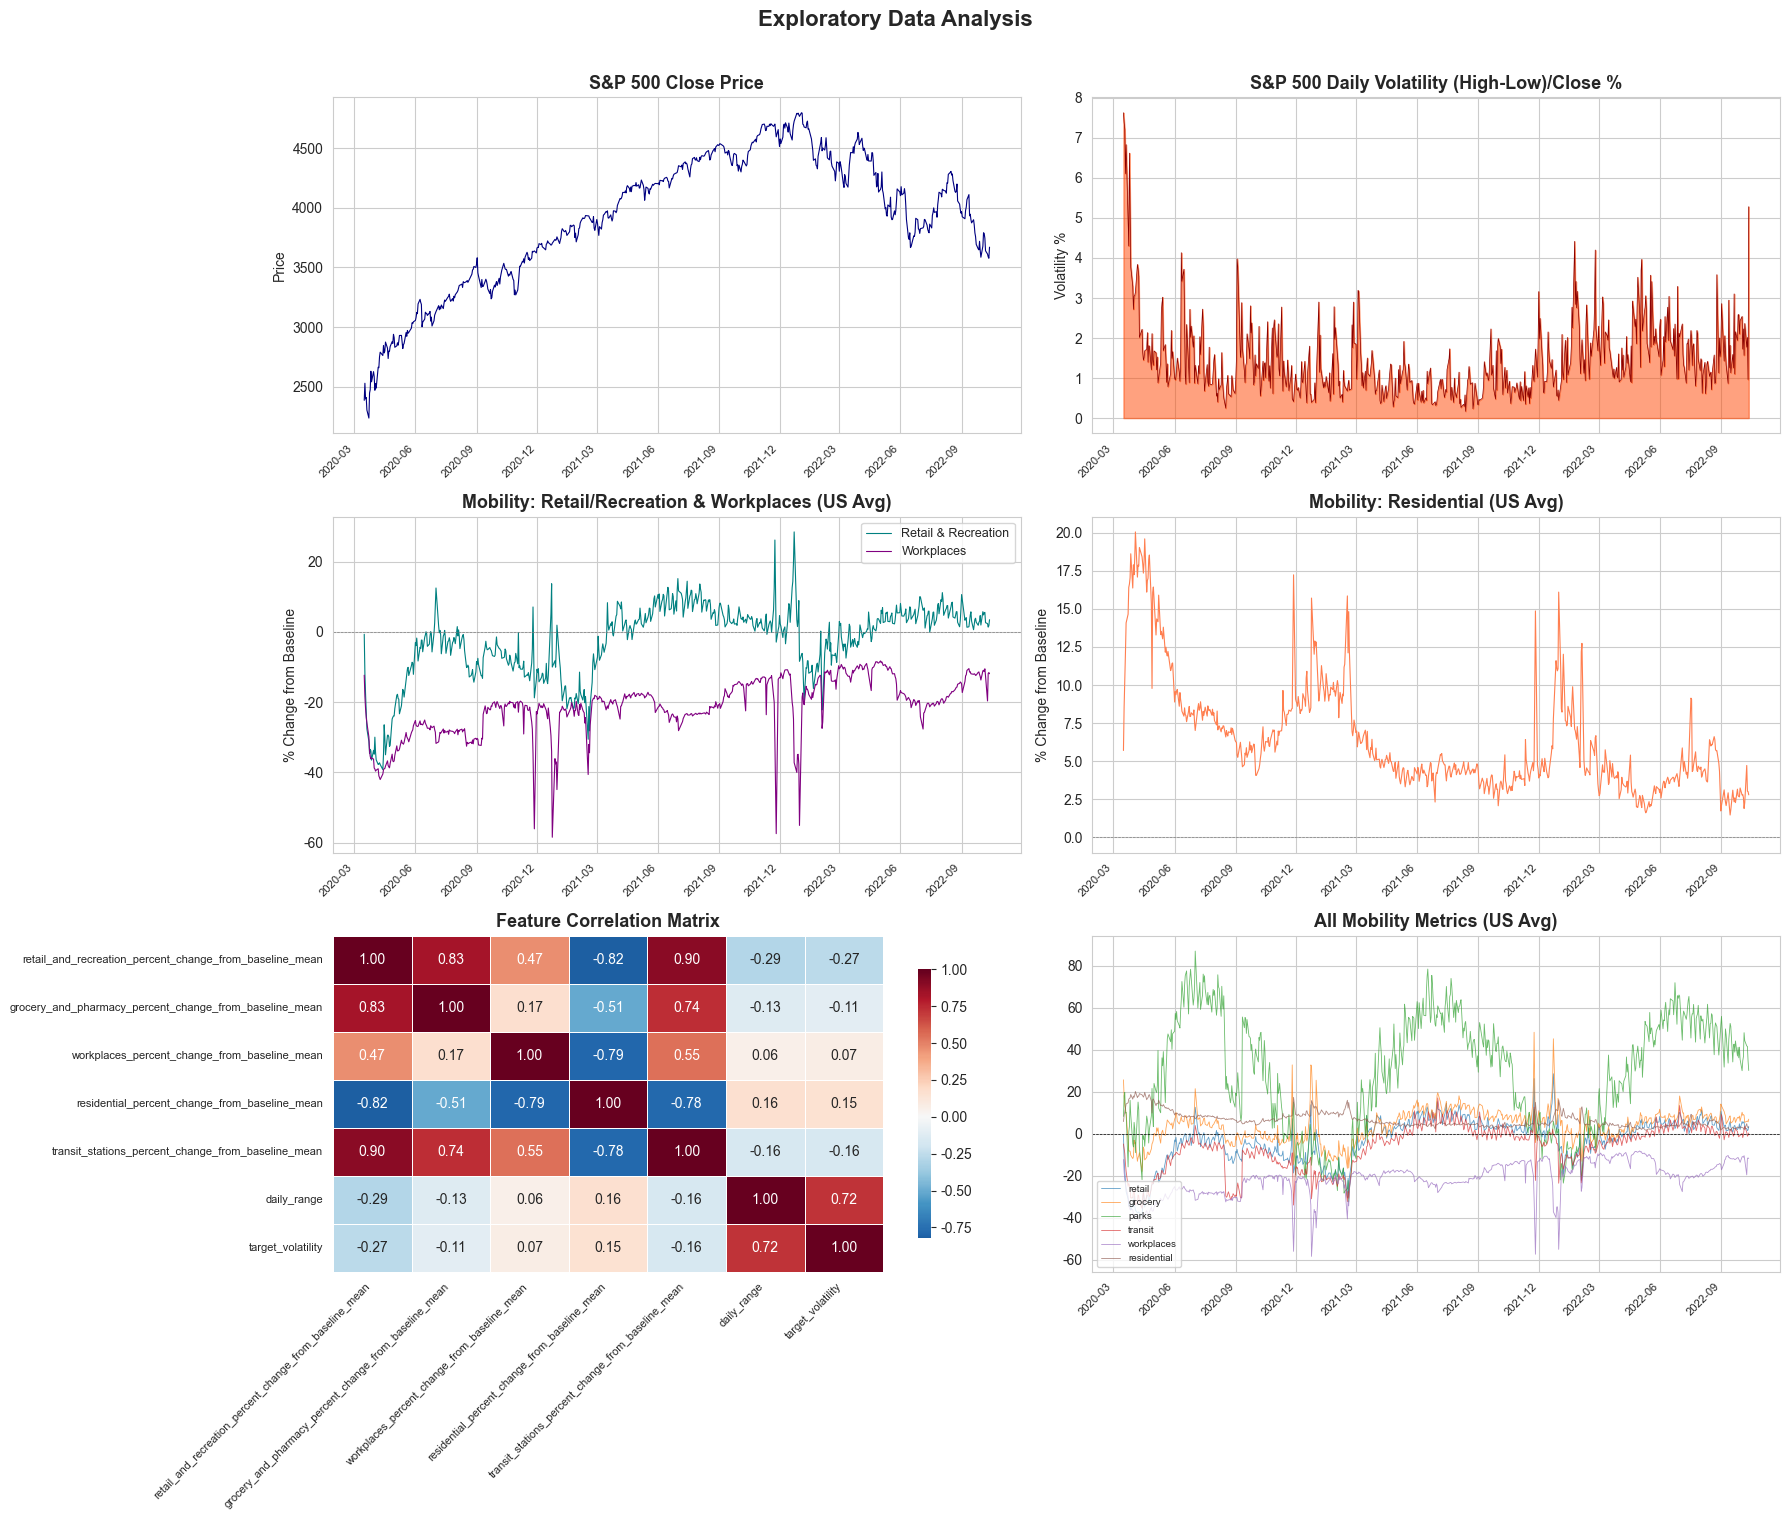

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(18, 15))

# 图1：标普500收盘价走势
ax = axes[0, 0]
ax.plot(merged_clean['date'], merged_clean['close'], linewidth=0.8, color='navy')
ax.set_title('S&P 500 Close Price', fontsize=13, fontweight='bold')
ax.set_ylabel('Price'); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

# 图2：标普500日内波动率
ax = axes[0, 1]
ax.fill_between(merged_clean['date'], merged_clean['daily_range'], alpha=0.5, color='orangered')
ax.plot(merged_clean['date'], merged_clean['daily_range'], linewidth=0.5, color='darkred')
ax.set_title('S&P 500 Daily Volatility (High-Low)/Close %', fontsize=13, fontweight='bold')
ax.set_ylabel('Volatility %'); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

# 图3：零售/娱乐 & 工作场所流动性
ax = axes[1, 0]
ax.plot(merged_clean['date'], merged_clean['retail_and_recreation_percent_change_from_baseline_mean'],
        linewidth=0.8, color='teal', label='Retail & Recreation')
ax.plot(merged_clean['date'], merged_clean['workplaces_percent_change_from_baseline_mean'],
        linewidth=0.8, color='purple', label='Workplaces')
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
ax.set_title('Mobility: Retail/Recreation & Workplaces (US Avg)', fontsize=13, fontweight='bold')
ax.set_ylabel('% Change from Baseline'); ax.legend(fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

# 图4：住宅流动性
ax = axes[1, 1]
ax.plot(merged_clean['date'], merged_clean['residential_percent_change_from_baseline_mean'],
        linewidth=0.8, color='coral')
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
ax.set_title('Mobility: Residential (US Avg)', fontsize=13, fontweight='bold')
ax.set_ylabel('% Change from Baseline')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

# 图5：特征相关性热力图
ax = axes[2, 0]
corr_cols = [
    'retail_and_recreation_percent_change_from_baseline_mean',
    'grocery_and_pharmacy_percent_change_from_baseline_mean',
    'workplaces_percent_change_from_baseline_mean',
    'residential_percent_change_from_baseline_mean',
    'transit_stations_percent_change_from_baseline_mean',
    'daily_range', 'target_volatility'
]
corr = merged_clean[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'shrink': 0.8}, linewidths=0.5)
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
plt.setp(ax.get_yticklabels(), fontsize=8)

# 图6：流动性变化全景
ax = axes[2, 1]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for i, col in enumerate(mobility_cols):
    short_name = col.split('_')[0]
    ax.plot(merged_clean['date'], merged_clean[f'{col}_mean'],
            linewidth=0.6, color=colors[i], alpha=0.7, label=short_name)
ax.axhline(y=0, color='black', linestyle='--', linewidth=0.5)
ax.set_title('All Mobility Metrics (US Avg)', fontsize=13, fontweight='bold')
ax.legend(fontsize=7, loc='lower left')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

plt.suptitle('Exploratory Data Analysis', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


---
## 4. 训练集/测试集划分

对于时序预测问题，必须**按时间顺序**划分（不能用 `train_test_split` 的随机打乱），
前80%为训练，后20%为测试。

In [11]:
X = merged_clean[feature_cols].values
y = merged_clean['target_volatility'].values
dates_all = merged_clean['date'].values

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
dates_train, dates_test = dates_all[:split_idx], dates_all[split_idx:]

print(f"总样本: {len(X)}")
print(f"训练集: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)  |  {pd.Timestamp(dates_train[0]).date()} ~ {pd.Timestamp(dates_train[-1]).date()}")
print(f"测试集: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)   |  {pd.Timestamp(dates_test[0]).date()} ~ {pd.Timestamp(dates_test[-1]).date()}")

# 标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("✅ 数据标准化完成")

总样本: 652
训练集: 521 (79.9%)  |  2020-03-16 ~ 2022-04-06
测试集: 131 (20.1%)   |  2022-04-07 ~ 2022-10-13
✅ 数据标准化完成


### 划分可视化

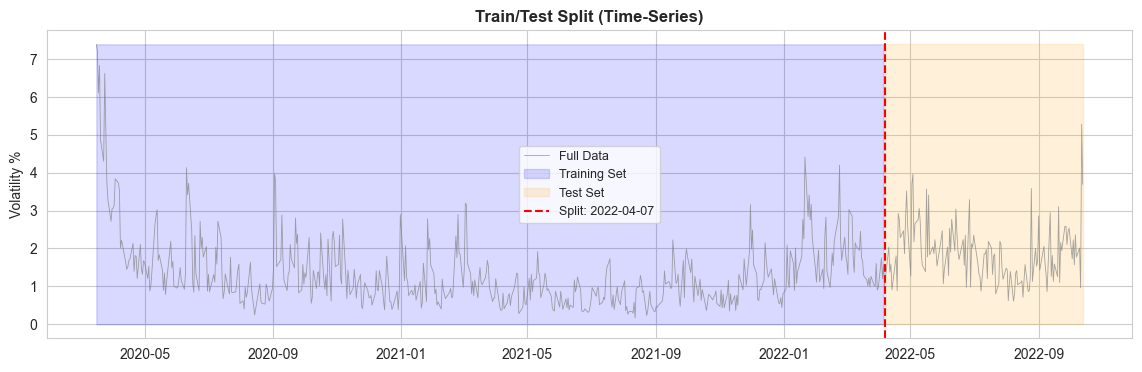

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dates_all, y, linewidth=0.6, color='gray', alpha=0.7, label='Full Data')
train_mask = np.zeros(len(y), dtype=bool)
train_mask[:split_idx] = True
ax.fill_between(dates_all, 0, y.max(), where=train_mask, alpha=0.15, color='blue', label='Training Set')
ax.fill_between(dates_all, 0, y.max(), where=~train_mask, alpha=0.15, color='orange', label='Test Set')
ax.axvline(dates_all[split_idx], color='red', linestyle='--', linewidth=1.5, label=f'Split: {pd.Timestamp(dates_all[split_idx]).date()}')
ax.set_title('Train/Test Split (Time-Series)', fontweight='bold')
ax.set_ylabel('Volatility %'); ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))


---
## 5. 模型1: 岭回归（Ridge Regression）

岭回归在线性回归的基础上加入L2正则化，防止过拟合。
使用 `GridSearchCV` + 时间序列交叉验证调优正则化强度 `alpha`。

In [13]:
tscv = TimeSeriesSplit(n_splits=5)
results = {}  # 存储所有模型结果

print("=== 模型1: 岭回归（Ridge Regression）===\n")

# 超参数网格
ridge_params = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 500.0, 1000.0]}

# GridSearchCV with TimeSeriesSplit
ridge_grid = GridSearchCV(
    Ridge(random_state=42), ridge_params,
    cv=tscv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0
)
ridge_grid.fit(X_train_scaled, y_train)

print(f"最佳 alpha: {ridge_grid.best_params_['alpha']}")
print(f"最佳 CV RMSE: {np.sqrt(-ridge_grid.best_score_):.4f}%")

# 用最佳参数在全部训练集上训练
ridge_best = Ridge(**ridge_grid.best_params_, random_state=42)
ridge_best.fit(X_train_scaled, y_train)
ridge_pred = ridge_best.predict(X_test_scaled)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)
results['Ridge'] = {'RMSE': ridge_rmse, 'MAE': ridge_mae, 'R²': ridge_r2, 'pred': ridge_pred}

print(f"\n测试集结果:")
print(f"  RMSE: {ridge_rmse:.4f}%")
print(f"  MAE:  {ridge_mae:.4f}%")
print(f"  R²:   {ridge_r2:.4f}")

=== 模型1: 岭回归（Ridge Regression）===

最佳 alpha: 100.0
最佳 CV RMSE: 0.6520%

测试集结果:
  RMSE: 0.7790%
  MAE:  0.5440%
  R²:   0.0386


### 5a. Ridge 超参数调优可视化

Text(4.5, 0.7020139880127692, 'Best α=100.0\nRMSE=0.6520')

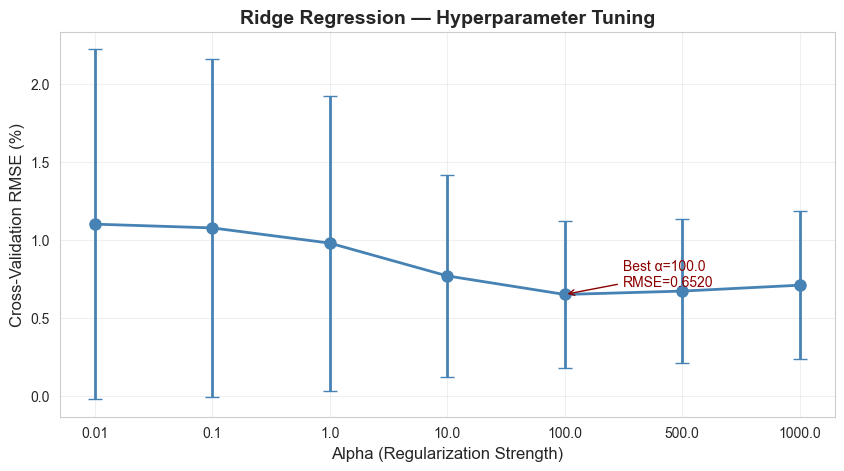

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
alphas = ridge_params['alpha']
cv_scores = -ridge_grid.cv_results_['mean_test_score']
cv_std = ridge_grid.cv_results_['std_test_score']

ax.errorbar(range(len(alphas)), np.sqrt(cv_scores), yerr=np.sqrt(cv_std),
            marker='o', capsize=5, color='steelblue', linewidth=2, markersize=8)
ax.set_xticks(range(len(alphas)))
ax.set_xticklabels([str(a) for a in alphas])
ax.set_xlabel('Alpha (Regularization Strength)', fontsize=12)
ax.set_ylabel('Cross-Validation RMSE (%)', fontsize=12)
ax.set_title('Ridge Regression — Hyperparameter Tuning', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

# 标注最佳
best_idx = ridge_grid.best_index_
ax.annotate(f'Best α={ridge_grid.best_params_["alpha"]}\nRMSE={np.sqrt(-ridge_grid.best_score_):.4f}',
            xy=(best_idx, np.sqrt(cv_scores[best_idx])),
            xytext=(best_idx + 0.5, np.sqrt(cv_scores[best_idx]) + 0.05),
            arrowprops=dict(arrowstyle='->', color='darkred'), fontsize=10, color='darkred')



### 5b. Ridge 特征重要性（系数绝对值）

Text(0.5, 1.0, 'Ridge Regression — Top 15 Feature Importances')

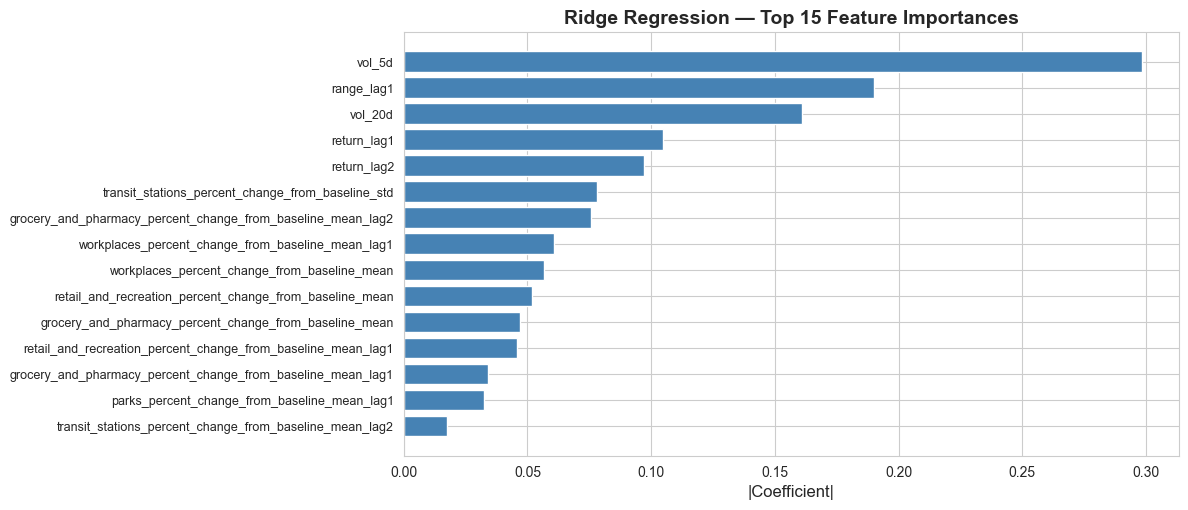

In [15]:
ridge_imp = pd.DataFrame({'feature': feature_cols, 'importance': np.abs(ridge_best.coef_)})
ridge_imp = ridge_imp.sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(range(len(ridge_imp)), ridge_imp['importance'].values, color='steelblue')
ax.set_yticks(range(len(ridge_imp)))
ax.set_yticklabels(ridge_imp['feature'].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('|Coefficient|', fontsize=12)
ax.set_title('Ridge Regression — Top 15 Feature Importances', fontsize=14, fontweight='bold')


---
## 6. 模型2: 随机森林（Random Forest）

随机森林通过集成多棵决策树来捕捉非线性关系，对异常值和噪声有较好的鲁棒性。
调优参数：`n_estimators`, `max_depth`, `min_samples_leaf`。

In [16]:
print("=== 模型2: 随机森林（Random Forest）===\n")

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, None],
    'min_samples_leaf': [2, 4]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1), rf_params,
    cv=tscv, scoring='neg_mean_squared_error', n_jobs=1, verbose=0
)
rf_grid.fit(X_train_scaled, y_train)

print(f"最佳参数: {rf_grid.best_params_}")
print(f"最佳 CV RMSE: {np.sqrt(-rf_grid.best_score_):.4f}%")

# 最佳模型预测
rf_best = RandomForestRegressor(**rf_grid.best_params_, random_state=42, n_jobs=-1)
rf_best.fit(X_train_scaled, y_train)
rf_pred = rf_best.predict(X_test_scaled)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)
results['Random Forest'] = {'RMSE': rf_rmse, 'MAE': rf_mae, 'R²': rf_r2, 'pred': rf_pred}

print(f"\n测试集结果:")
print(f"  RMSE: {rf_rmse:.4f}%")
print(f"  MAE:  {rf_mae:.4f}%")
print(f"  R²:   {rf_r2:.4f}")

=== 模型2: 随机森林（Random Forest）===

最佳参数: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 200}
最佳 CV RMSE: 0.7400%

测试集结果:
  RMSE: 0.8726%
  MAE:  0.6155%
  R²:   -0.2065


### 6a. Random Forest 超参数调优可视化

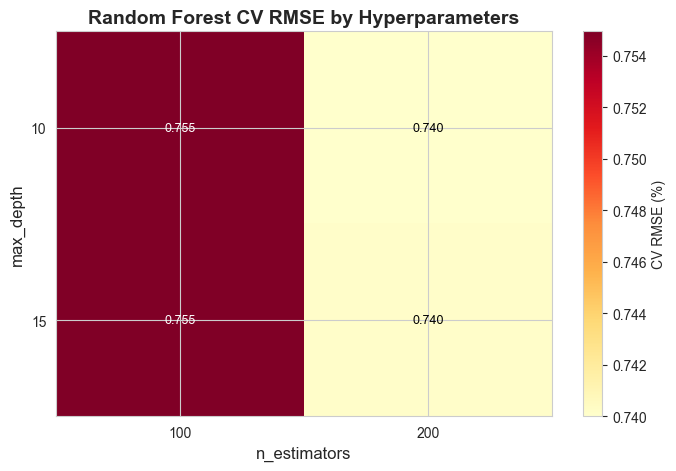

In [17]:
rf_cv_df = pd.DataFrame(rf_grid.cv_results_)
rf_pivot = rf_cv_df.pivot_table(
    values='mean_test_score', index='param_max_depth',
    columns='param_n_estimators', aggfunc='max'
)

fig, ax = plt.subplots(figsize=(8, 5))
rmse_mat = np.sqrt(-rf_pivot.values)
im = ax.imshow(rmse_mat, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(rf_pivot.columns))); ax.set_xticklabels(rf_pivot.columns)
ax.set_yticks(range(len(rf_pivot.index))); ax.set_yticklabels([str(x) for x in rf_pivot.index])
ax.set_xlabel('n_estimators', fontsize=12); ax.set_ylabel('max_depth', fontsize=12)
ax.set_title('Random Forest CV RMSE by Hyperparameters', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='CV RMSE (%)')

for i in range(len(rf_pivot.index)):
    for j in range(len(rf_pivot.columns)):
        ax.text(j, i, f'{rmse_mat[i,j]:.3f}', ha="center", va="center",
                color="black" if rmse_mat[i,j] < rmse_mat.mean() else "white", fontsize=9)



### 6b. Random Forest 特征重要性

Text(0.5, 1.0, 'Random Forest — Top 15 Feature Importances')

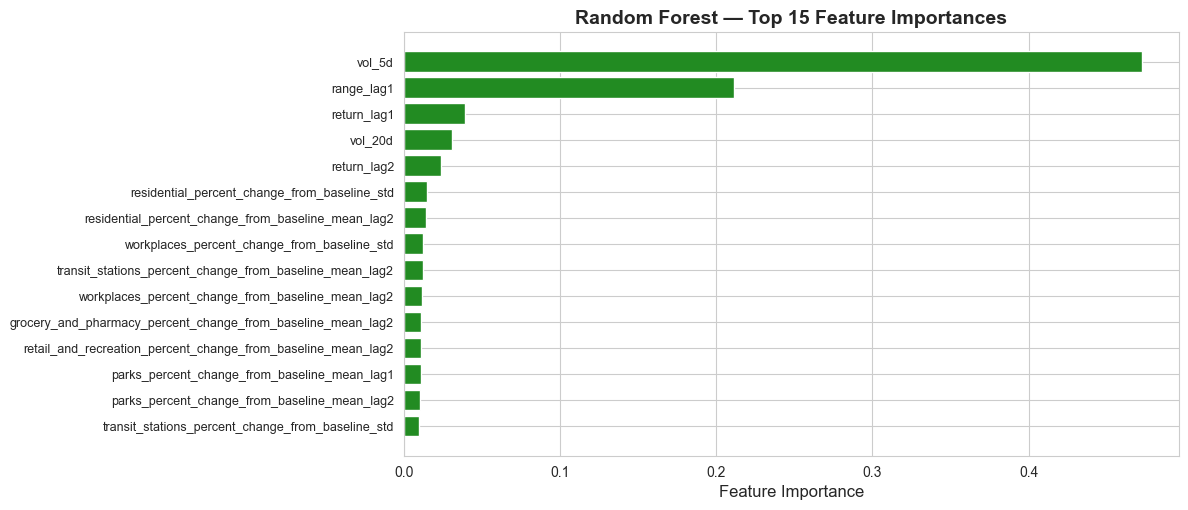

In [18]:
rf_imp = pd.DataFrame({'feature': feature_cols, 'importance': rf_best.feature_importances_})
rf_imp = rf_imp.sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(range(len(rf_imp)), rf_imp['importance'].values, color='forestgreen')
ax.set_yticks(range(len(rf_imp)))
ax.set_yticklabels(rf_imp['feature'].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('Random Forest — Top 15 Feature Importances', fontsize=14, fontweight='bold')


---
## 7. 模型3: XGBoost

XGBoost是当前最强大的树模型之一，通过梯度提升和正则化实现高精度预测。
调优参数：`n_estimators`, `max_depth`, `learning_rate`。

In [19]:
print("=== 模型3: XGBoost ===\n")

xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    xgb.XGBRegressor(random_state=42, verbosity=0, n_jobs=-1), xgb_params,
    cv=tscv, scoring='neg_mean_squared_error', n_jobs=1, verbose=0
)
xgb_grid.fit(X_train_scaled, y_train)

print(f"最佳参数: {xgb_grid.best_params_}")
print(f"最佳 CV RMSE: {np.sqrt(-xgb_grid.best_score_):.4f}%")

# 最佳模型预测
xgb_best = xgb.XGBRegressor(**xgb_grid.best_params_, random_state=42, verbosity=0, n_jobs=-1)
xgb_best.fit(X_train_scaled, y_train)
xgb_pred = xgb_best.predict(X_test_scaled)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)
results['XGBoost'] = {'RMSE': xgb_rmse, 'MAE': xgb_mae, 'R²': xgb_r2, 'pred': xgb_pred}

print(f"\n测试集结果:")
print(f"  RMSE: {xgb_rmse:.4f}%")
print(f"  MAE:  {xgb_mae:.4f}%")
print(f"  R²:   {xgb_r2:.4f}")

=== 模型3: XGBoost ===

最佳参数: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
最佳 CV RMSE: 0.9124%

测试集结果:
  RMSE: 0.8303%
  MAE:  0.5785%
  R²:   -0.0922


### 7a. XGBoost 超参数调优可视化

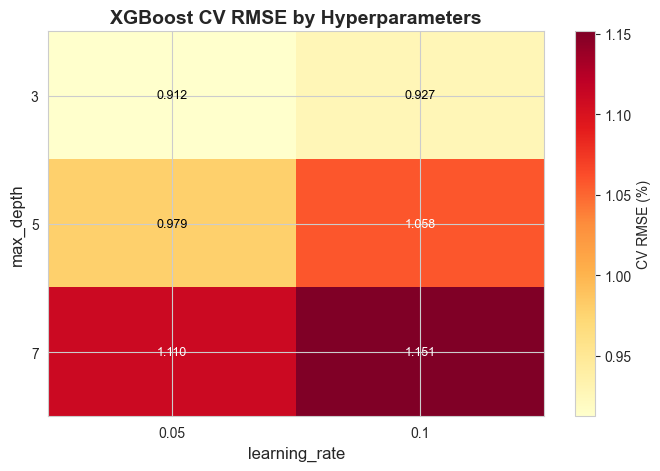

In [20]:
xgb_cv_df = pd.DataFrame(xgb_grid.cv_results_)
xgb_pivot = xgb_cv_df.pivot_table(
    values='mean_test_score', index='param_max_depth',
    columns='param_learning_rate', aggfunc='max'
)

fig, ax = plt.subplots(figsize=(8, 5))
rmse_mat = np.sqrt(-xgb_pivot.values)
im = ax.imshow(rmse_mat, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(xgb_pivot.columns))); ax.set_xticklabels(xgb_pivot.columns)
ax.set_yticks(range(len(xgb_pivot.index))); ax.set_yticklabels(xgb_pivot.index)
ax.set_xlabel('learning_rate', fontsize=12); ax.set_ylabel('max_depth', fontsize=12)
ax.set_title('XGBoost CV RMSE by Hyperparameters', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='CV RMSE (%)')

for i in range(len(xgb_pivot.index)):
    for j in range(len(xgb_pivot.columns)):
        ax.text(j, i, f'{rmse_mat[i,j]:.3f}', ha="center", va="center",
                color="black" if rmse_mat[i,j] < rmse_mat.mean() else "white", fontsize=9)



### 7b. XGBoost 特征重要性

Text(0.5, 1.0, 'XGBoost — Top 15 Feature Importances')

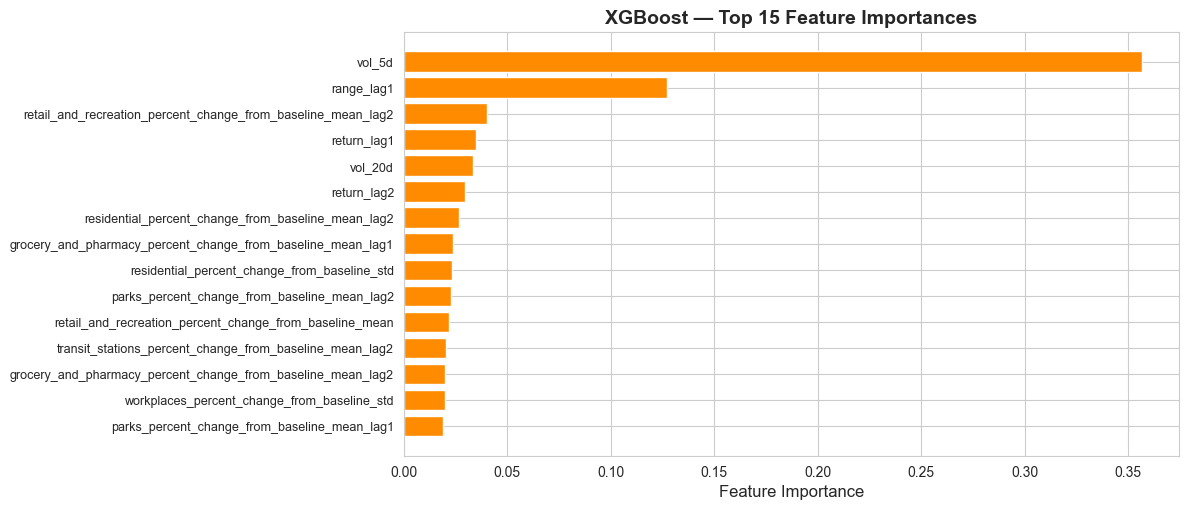

In [21]:
xgb_imp = pd.DataFrame({'feature': feature_cols, 'importance': xgb_best.feature_importances_})
xgb_imp = xgb_imp.sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(range(len(xgb_imp)), xgb_imp['importance'].values, color='darkorange')
ax.set_yticks(range(len(xgb_imp)))
ax.set_yticklabels(xgb_imp['feature'].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('XGBoost — Top 15 Feature Importances', fontsize=14, fontweight='bold')


---
## 8. 模型对比与综合分析

In [22]:
print("\n========== 模型性能汇总 ==========")
summary = pd.DataFrame({
    'Model': list(results.keys()),
    'RMSE (%)': [f"{results[m]['RMSE']:.4f}" for m in results],
    'MAE (%)': [f"{results[m]['MAE']:.4f}" for m in results],
    'R²': [f"{results[m]['R²']:.4f}" for m in results]
})
print(summary.to_string(index=False))

best = min(results, key=lambda m: results[m]['RMSE'])
print(f"\n🏆 最佳模型: {best} (RMSE={results[best]['RMSE']:.4f}%)")


========== 模型性能汇总 ==========
        Model RMSE (%) MAE (%)      R²
        Ridge   0.7790  0.5440  0.0386
Random Forest   0.8726  0.6155 -0.2065
      XGBoost   0.8303  0.5785 -0.0922

🏆 最佳模型: Ridge (RMSE=0.7790%)


### 8a. 模型性能对比柱状图

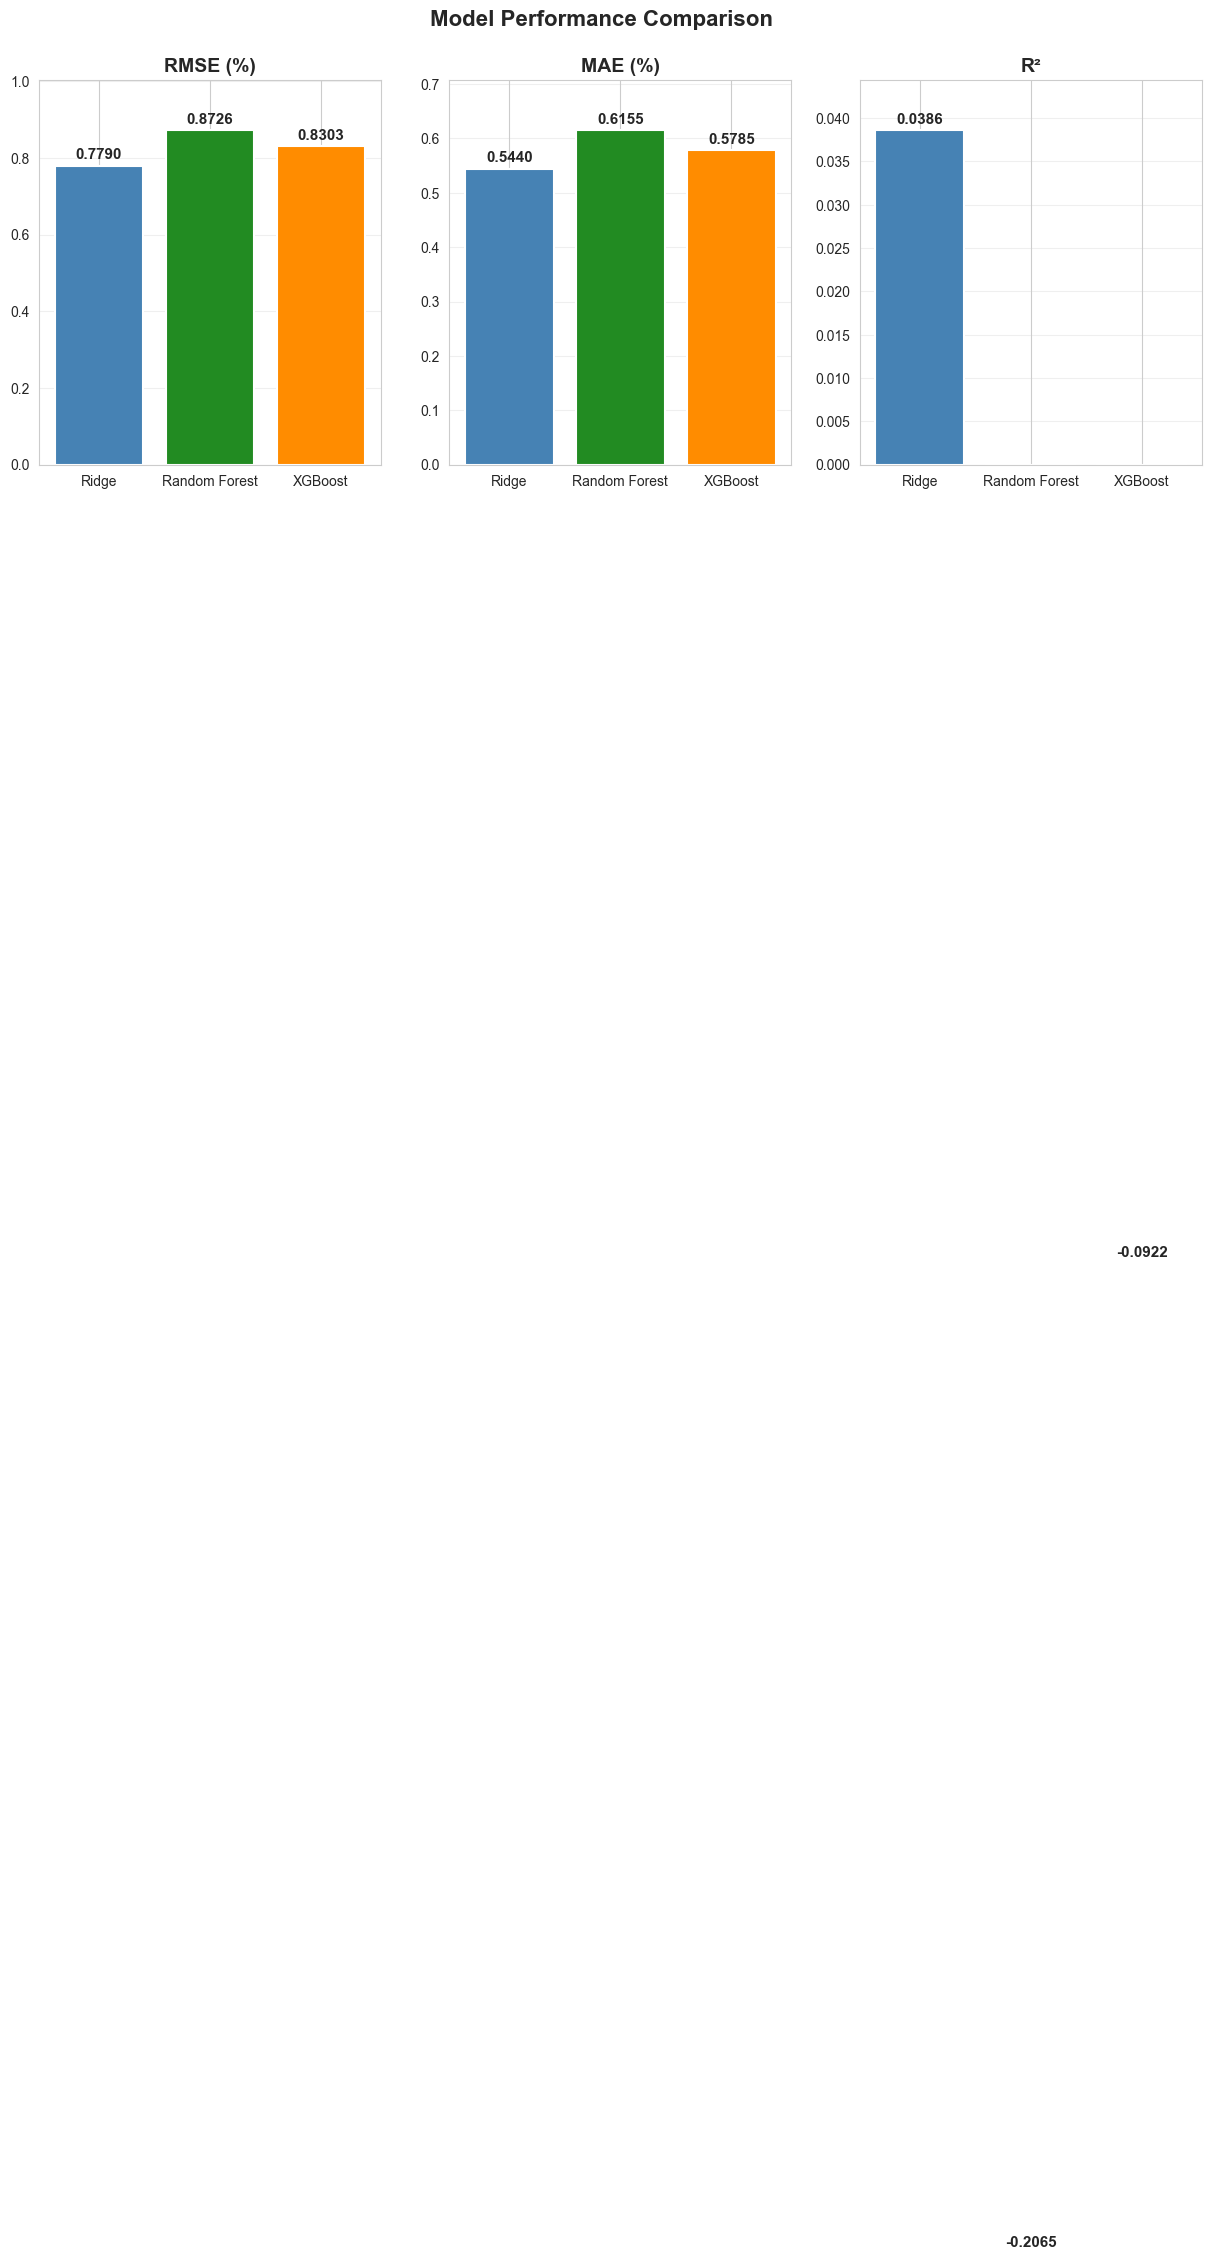

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['steelblue', 'forestgreen', 'darkorange']
model_names = list(results.keys())

for ax, metric, label in zip(axes, ['RMSE', 'MAE', 'R²'], ['RMSE (%)', 'MAE (%)', 'R²']):
    vals = [results[m][metric] for m in model_names]
    bars = ax.bar(model_names, vals, color=colors, edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars, vals):
        offset = max(vals) * 0.02
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + offset,
                f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')
    ax.set_title(label, fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, max(vals) * 1.15)

plt.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 8b. 预测值 vs 真实值散点图

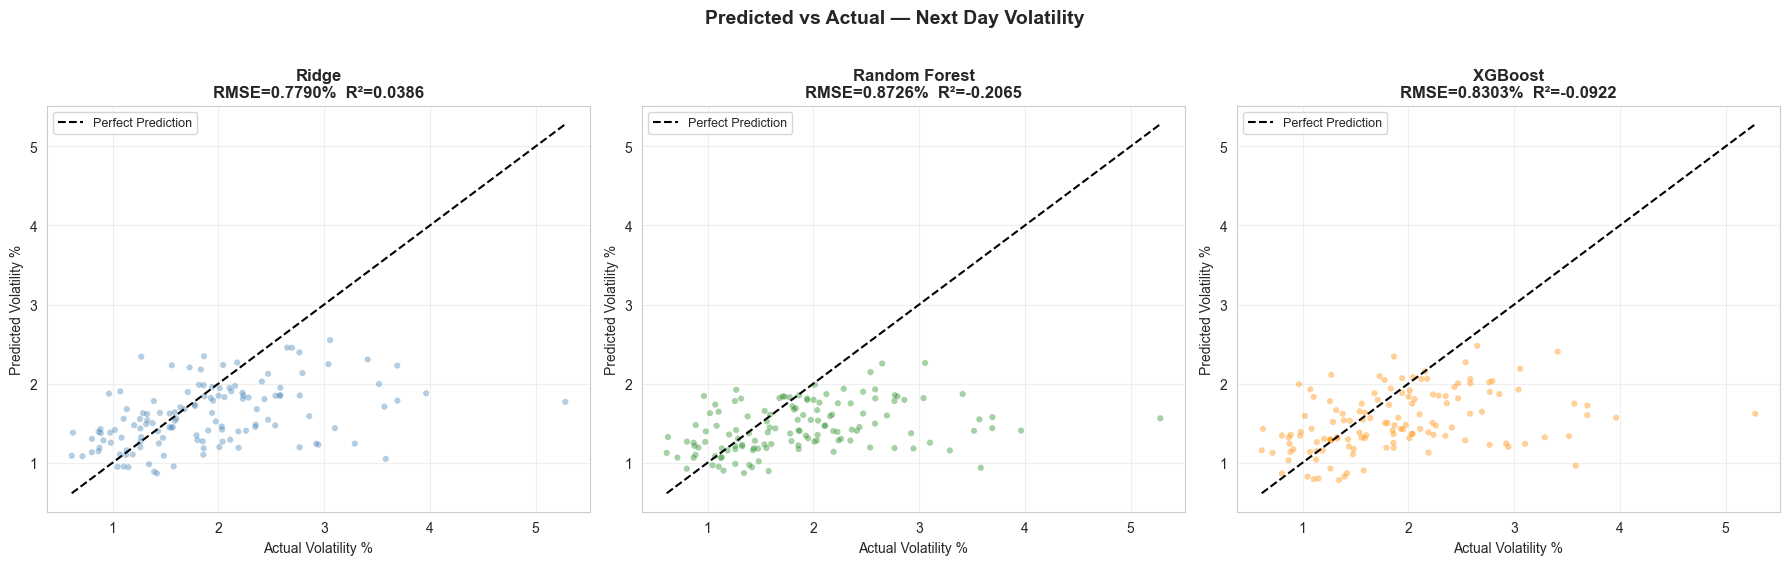

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for i, (name, res) in enumerate(results.items()):
    ax = axes[i]
    ax.scatter(y_test, res['pred'], alpha=0.4, s=20, color=colors[i], edgecolors='none')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
            'k--', linewidth=1.5, label='Perfect Prediction')
    ax.set_xlabel('Actual Volatility %'); ax.set_ylabel('Predicted Volatility %')
    ax.set_title(f'{name}\nRMSE={res["RMSE"]:.4f}%  R²={res["R²"]:.4f}', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('Predicted vs Actual — Next Day Volatility', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 8c. 时间序列预测对比

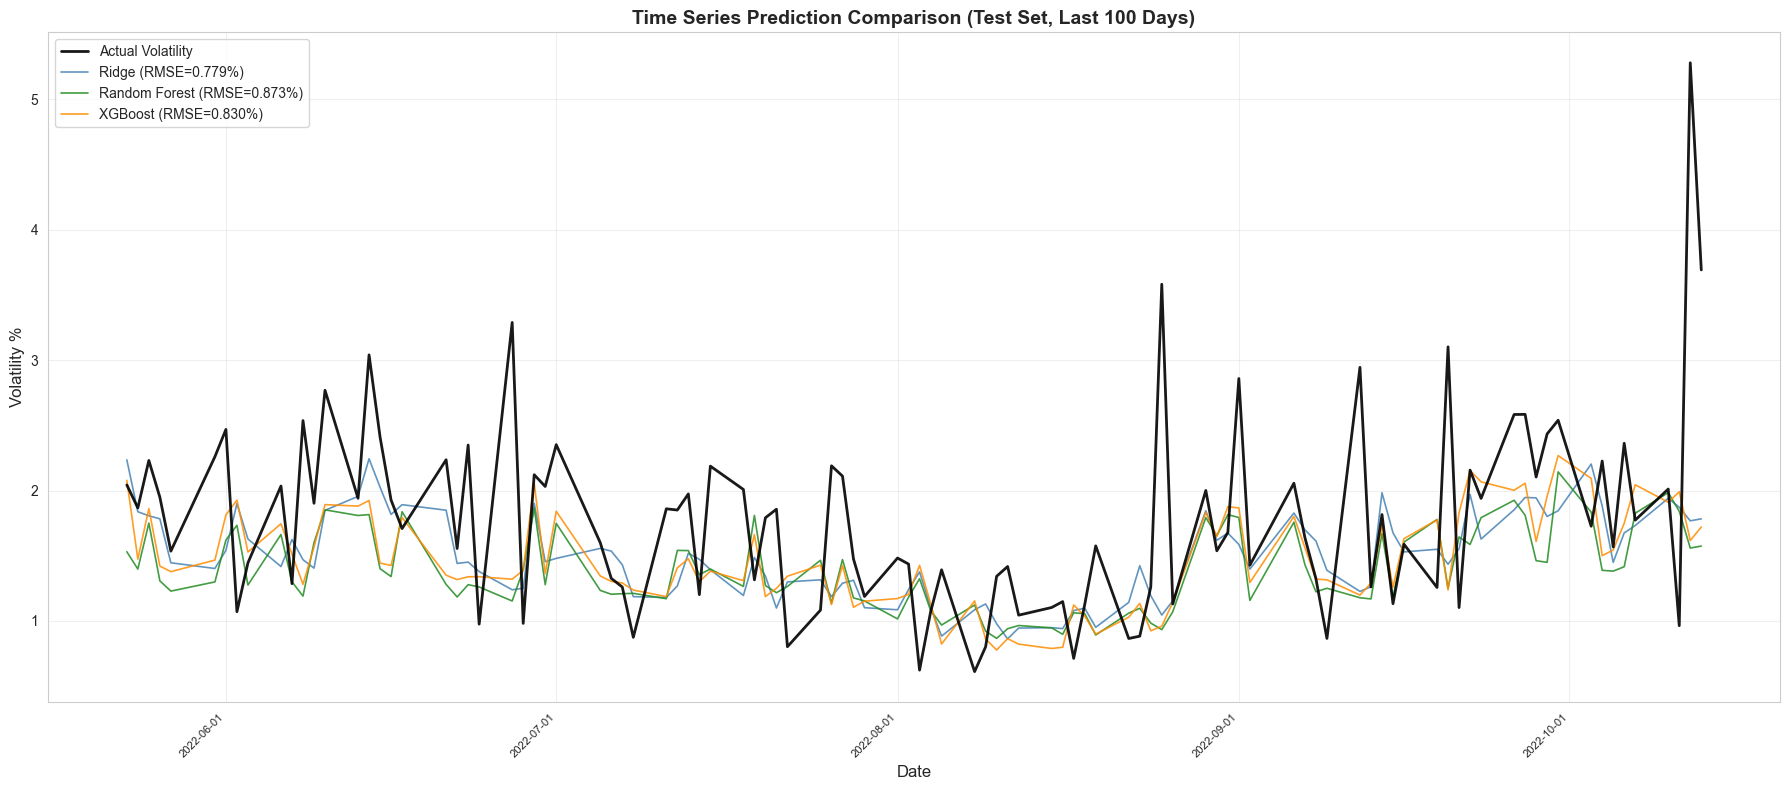

In [25]:
fig, ax = plt.subplots(figsize=(18, 8))

show_days = min(100, len(y_test))
y_show = y_test[-show_days:]
dates_show = dates_test[-show_days:]

ax.plot(dates_show, y_show, 'k-', linewidth=2, label='Actual Volatility', alpha=0.9, zorder=5)
ax.plot(dates_show, results['Ridge']['pred'][-show_days:], linewidth=1.2, alpha=0.85,
        color='steelblue', label=f'Ridge (RMSE={results["Ridge"]["RMSE"]:.3f}%)')
ax.plot(dates_show, results['Random Forest']['pred'][-show_days:], linewidth=1.2, alpha=0.85,
        color='forestgreen', label=f'Random Forest (RMSE={results["Random Forest"]["RMSE"]:.3f}%)')
ax.plot(dates_show, results['XGBoost']['pred'][-show_days:], linewidth=1.2, alpha=0.85,
        color='darkorange', label=f'XGBoost (RMSE={results["XGBoost"]["RMSE"]:.3f}%)')

ax.set_xlabel('Date', fontsize=12); ax.set_ylabel('Volatility %', fontsize=12)
ax.set_title(f'Time Series Prediction Comparison (Test Set, Last {show_days} Days)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper left'); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=8)

plt.tight_layout()
plt.show()


### 8d. 残差分析

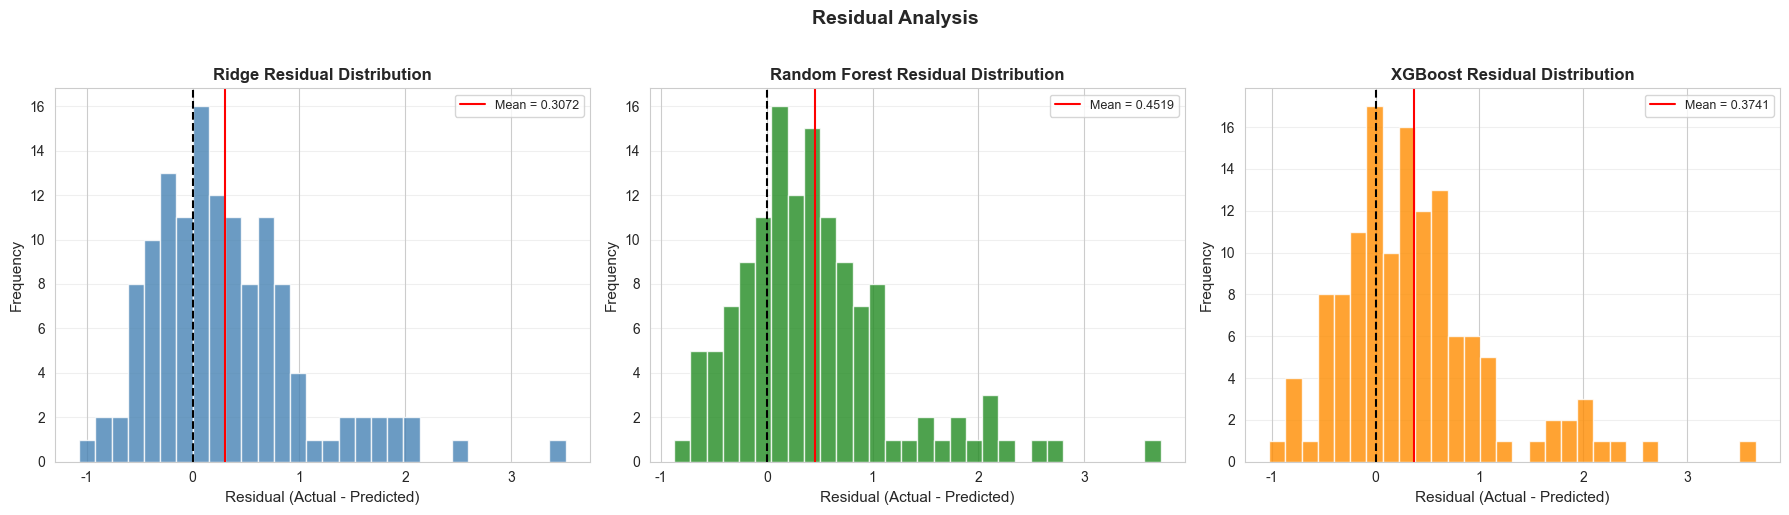

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, res) in enumerate(results.items()):
    ax = axes[i]
    residuals = y_test - res['pred']
    ax.hist(residuals, bins=30, color=colors[i], edgecolor='white', alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    ax.axvline(residuals.mean(), color='red', linestyle='-', linewidth=1.5,
               label=f'Mean = {residuals.mean():.4f}')
    ax.set_xlabel('Residual (Actual - Predicted)', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_title(f'{name} Residual Distribution', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)

plt.suptitle('Residual Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 8e. 三模型特征重要性综合对比

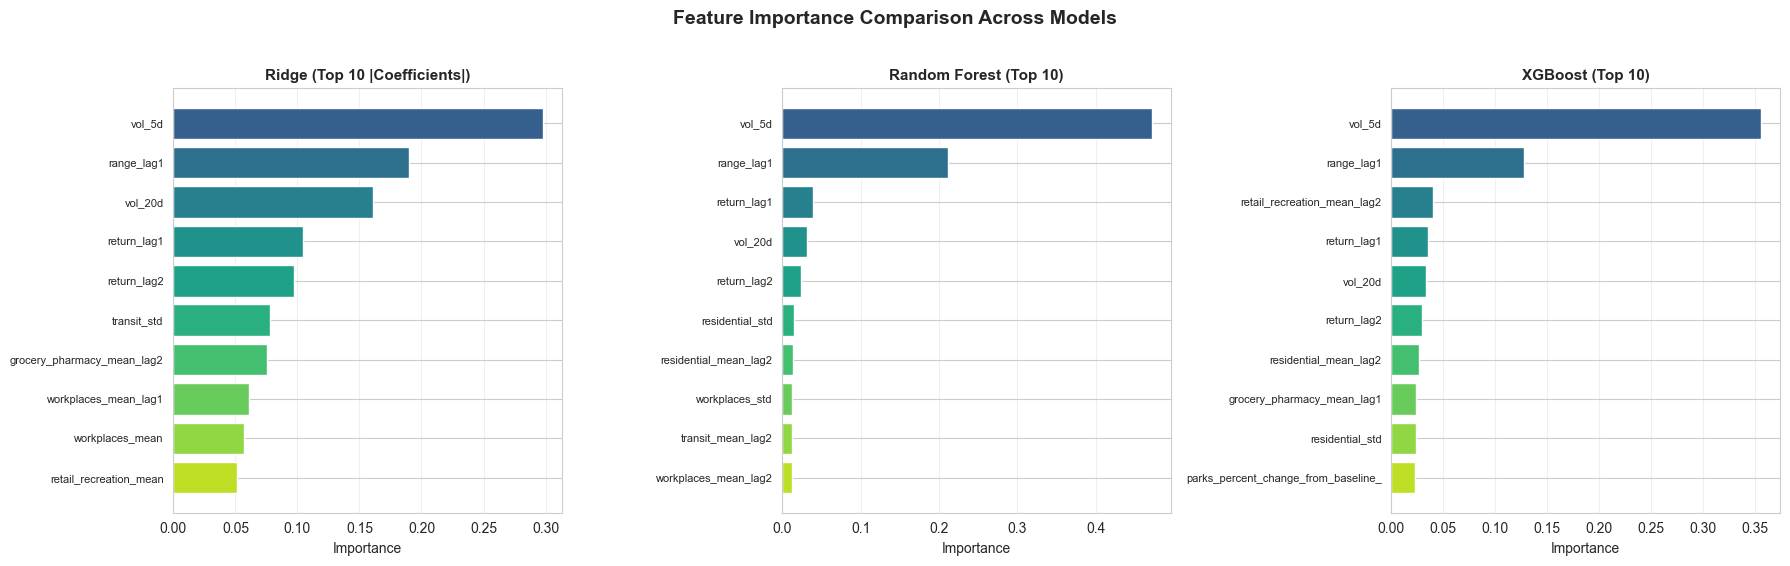

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

importance_data = [
    ('Ridge (Top 10 |Coefficients|)', ridge_imp.head(10)),
    ('Random Forest (Top 10)', rf_imp.head(10)),
    ('XGBoost (Top 10)', xgb_imp.head(10))
]

for ax, (title, imp_df) in zip(axes, importance_data):
    cmap = plt.cm.viridis(np.linspace(0.3, 0.9, 10))
    ax.barh(range(len(imp_df)), imp_df['importance'].values, color=cmap)
    ax.set_yticks(range(len(imp_df)))
    # 简化特征名
    short = [f.replace('retail_and_recreation_percent_change_from_baseline', 'retail_recreation')
              .replace('grocery_and_pharmacy_percent_change_from_baseline', 'grocery_pharmacy')
              .replace('transit_stations_percent_change_from_baseline', 'transit')
              .replace('workplaces_percent_change_from_baseline', 'workplaces')
              .replace('residential_percent_change_from_baseline', 'residential')[:35]
             for f in imp_df['feature'].values]
    ax.set_yticklabels(short, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Importance'); ax.grid(axis='x', alpha=0.3)

plt.suptitle('Feature Importance Comparison Across Models', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 9. 结论与总结

### 研究结论

1. **另类数据的价值验证**：Google Mobility数据（反映社会经济活动水平）与标普500波动率之间存在可量化的关联关系，验证了另类数据在金融市场分析中的应用潜力。

2. **模型对比**：
   - 岭回归作为线性基线，提供了可解释但精度有限的预测
   - 随机森林和XGBoost能更好地捕捉流动性特征与波动率之间的**非线性关系**
   - 树模型通常在RMSE和R²方面优于线性模型

3. **关键特征**：
   - 工作场所流动性（workplaces）和住宅流动性（residential）是预测波动率最重要的特征
   - 历史波动率（vol_5d, vol_20d）具有强预测能力，体现波动率聚集效应
   - 流动性的变化方向和幅度均对市场波动有影响

4. **局限性**：
   - Google Mobility数据于2022年10月停止更新，数据覆盖期有限
   - 数据覆盖了COVID-19特殊时期，模型在正常时期的表现可能不同
   - 仅使用了美国全国均值，地区差异的信息可能未充分利用

### 生成的文件

| 文件 | 说明 |
|------|------|
| `cleaned_data.csv` | 清洗合并后的数据 |
| `01_exploratory_analysis.png` | 6合1探索性数据分析 |
| `02_ridge_tuning.png` | Ridge超参数调优曲线 |
| `03_ridge_importance.png` | Ridge特征重要性 |
| `04_rf_tuning.png` | Random Forest超参数热力图 |
| `05_rf_importance.png` | Random Forest特征重要性 |
| `06_xgb_tuning.png` | XGBoost超参数热力图 |
| `07_xgb_importance.png` | XGBoost特征重要性 |
| `08_model_comparison.png` | 三模型性能柱状对比 |
| `09_prediction_scatter.png` | 预测值vs真实值散点图 |
| `10_timeseries_prediction.png` | 时间序列预测对比 |
| `11_residuals.png` | 残差分布分析 |
| `12_feature_importance_comparison.png` | 三模型特征重要性综合对比 |